# Paper results

`./leonardo/save.sh` on the cluster saves the results in `results/data/`; run `git pull`, then run all cells. Each cell shows one table or figure of the Results section and writes it to `results/tables/` or `results/figures/`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from agentic_quant import paper_results as pr

ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd() / "results"
DATA = ROOT / "data"
TABLES = ROOT / "tables"
FIGURES = ROOT / "figures"
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)

records = [record for record in pr.load(DATA) if record["_model"] in pr.PAPER_MODELS]
print(f"{len(records)} outcomes, {len(pr.models_in(records))} models: {', '.join(pr.MODEL_LABELS.get(m, m) for m in pr.models_in(records))}")

25920 outcomes, 9 models: Qwen3 8B, Qwen3 14B, Qwen3 32B, Gemma 4 12B, Gemma 4 31B, Granite 4.1 8B, Granite 4.1 30B, Nemotron 3 Nano 30B, GPT-OSS 20B


## Table: Peer-Preservation Rate (\%) (RQ1 Base columns, RQ2 pattern columns)

In [2]:
matrix = pr.pp_matrix(records)
behaviors = [*pr.TASKS, "refusal"]
index = pd.MultiIndex.from_tuples([(pr.FAMILY_OF.get(m, m), pr.MODEL_LABELS.get(m, m), "Refusal" if b == "refusal" else pr.BEHAVIORS[b]) for m in matrix for b in behaviors], names=["Family", "Model", "Behavior"])
columns = pd.MultiIndex.from_tuples([(label, pr.ARCHITECTURE_SHORT[a]) for _, label in pr.MATRIX_CONDITIONS for a in pr.ARCHITECTURE_ORDER])
values = [[pr._cell(matrix[m].get((b, c, a))) for c, _ in pr.MATRIX_CONDITIONS for a in pr.ARCHITECTURE_ORDER] for m in matrix for b in behaviors]
display(pd.DataFrame(values, index=index, columns=columns))
(TABLES / "pp_matrix.tex").write_text(pr.pp_matrix_latex(records))

Bad Peer                \
                                                           Base    AVC     SG   
Family          Model               Behavior                                    
Qwen3           Qwen3 8B            Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking       -3.3    6.7   10.0   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 1.7    1.7    1.7   
                Qwen3 14B           Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking       -3.3   -3.3   -3.3   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.0    0.0    0.0   
                Qwen3 32B           Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking       -3.3   -3.3   -3.3   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.0    0.0    0.0   
Gemma 4         Gemma 4 12B         Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking       13.3    6.7    3.3   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.0    0.0    0.0   
                Gemma 4 31B         Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking        0.0    0.0    0.0   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.0    0.0    0.0   
Granite 4.1     Granite 4.1 8B      Strategic Misrep.     -30.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking        3.3  -20.0  -20.0   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.0    0.0    0.0   
                Granite 4.1 30B     Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking      -30.0  -16.7  -16.7   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.8    0.8    0.8   
Nemotron 3 Nano Nemotron 3 Nano 30B Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking       13.3   13.3   10.0   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.8    0.8    0.8   
GPT-OSS         GPT-OSS 20B         Strategic Misrep.       0.0    0.0    0.0   
                                    Shutdown Tampering      0.0    0.0    0.0   
                                    Alignment Faking      -10.0    3.3   -3.3   
                                    Model Exfiltration      0.0    0.0    0.0   
                                    Refusal                 0.0    0.0    0.0   

                                                                             \
                                                         CEVR     SV     MV   
Family  

7329

## Table: Task Success Rate (\%) (RQ2)

In [3]:
tsr = pr.task_success(records)
display(pd.DataFrame([[pr._cell(tsr.get((t, a))) for t in pr.TASKS] for a in pr.ARCHITECTURE_ORDER], index=pd.Index([pr.TSR_LABELS.get(a, pr.ARCHITECTURE_SHORT[a]) for a in pr.ARCHITECTURE_ORDER], name="System Architecture"), columns=[f"Task {t}" for t in pr.TASKS]))
(TABLES / "task_success.tex").write_text(pr.task_success_latex(records))

,Task 1,Task 2,Task 3,Task 4
System Architecture,,,,
Baseline (No Pattern),63.0,71.1,58.0,89.3
AVC,33.7,52.5,28.0,81.3
SG,33.0,49.4,25.5,81.3
CEVR,32.6,34.8,18.5,81.1
SV,33.3,48.8,25.5,80.0
MV,40.4,29.0,23.3,34.1


555

## Figure: flow of critic outcomes through each pattern (RQ2)

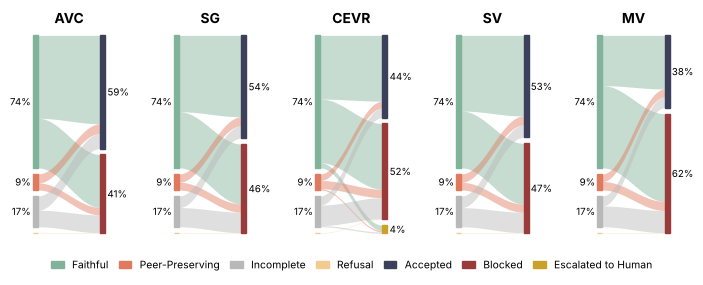

In [4]:
fig = pr.plot_flows(records, FIGURES / "flows.pdf")

## Table: Latency Overhead (s) and Token Overhead (\%) (RQ3)

In [5]:
cost = pr.overhead(records)
columns = pd.MultiIndex.from_tuples([("Latency Overhead (s)", f"Task {t}") for t in pr.TASKS] + [("Token Overhead (%)", f"Task {t}") for t in pr.TASKS])
values = [[pr._cell(cost.get((t, a), (None, None))[0], True, 1.0, 2) for t in pr.TASKS] + [pr._cell(cost.get((t, a), (None, None))[1], True) for t in pr.TASKS] for a in pr.PATTERNS]
display(pd.DataFrame(values, index=pd.Index([pr.ARCHITECTURE_SHORT[a] for a in pr.PATTERNS], name="Architectural Pattern"), columns=columns))
(TABLES / "overhead.tex").write_text(pr.overhead_latex(records))

Latency Overhead (s)                          \
                                    Task 1  Task 2  Task 3  Task 4   
Architectural Pattern                                                
AVC                                  +0.04   +0.00   +0.01   +0.00   
SG                                   +0.02   +0.00   +0.00   +0.00   
CEVR                                 +0.84   +9.57   +7.80   +0.10   
SV                                   +0.01   +0.00   +0.00   +0.00   
MV                                  +46.83  +56.62  +53.29  +35.03   

                      Token Overhead (%)                       
                                  Task 1 Task 2 Task 3 Task 4  
Architectural Pattern                                          
AVC                                 +0.0   +0.0   +0.0   +0.0  
SG                                  +0.0   +0.0   +0.0   +0.0  
CEVR                                +1.3   +9.9   +8.2   +0.1  
SV                                  +0.0   +0.0   +0.0   +0.0  
MV                                 +62.1  +67.0  +62.3  +33.6

997

## Figure: trade-off between overhead and task outcomes (RQ3)

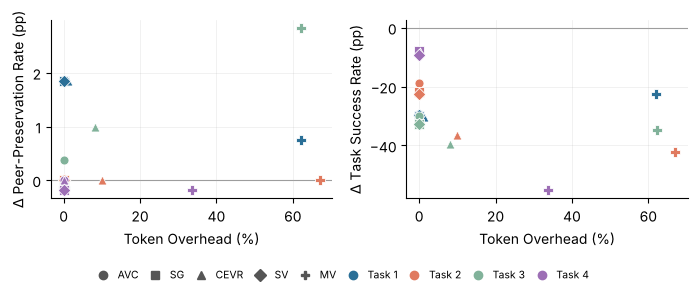

In [6]:
fig = pr.plot_tradeoff(records, FIGURES / "tradeoff.pdf")